# Alquiler - 01 EDA

Exploracion inicial de los datos de alquiler inmobiliario en Moscu.

Objetivo: entender estructura, calidad, variables disponibles y posibles relaciones con el alquiler mensual.

In [1]:
%pip install -r ../requirements.txt

  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached statsmodels-0.15.0-cp313-cp313-win_amd64.whl.metadata (9.6 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached pyyaml-6.0.3-cp313-cp313-win_amd64.whl.metadata (2.4 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached wrapt-2.5.0-cp313-cp313-win_amd64.whl.metadata (7.7 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached statsmodels-0.15.0-cp313-cp313-win_amd64.whl (11.3 MB)
Using cached formulaic-1.2.2-p


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

DATA_DIR = Path('..') / 'Data'

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

## Carga de datos

In [3]:
rentals = pd.read_csv(DATA_DIR / 'rentals.csv')
district_prices = pd.read_csv(DATA_DIR / 'district_prices_monthly.csv')
metro = pd.read_csv(DATA_DIR / 'metro_stations.csv')

datasets = {
    'rentals': rentals,
    'district_prices_monthly': district_prices,
    'metro_stations': metro,
}

for name, df in datasets.items():
    print(f'{name}: {df.shape[0]:,} filas x {df.shape[1]:,} columnas')

rentals: 20,000 filas x 22 columnas
district_prices_monthly: 9,804 filas x 13 columnas
metro_stations: 104 filas x 6 columnas


In [4]:
display(rentals.head())
display(district_prices.head())
display(metro.head())

,id,date_posted,district,okrug,lat,lon,total_area,rooms,floor,total_floors,building_year,building_type,renovation,furnished,pets_allowed,deposit_months,metro_station,metro_line,metro_distance_min,to_center_km,monthly_rent_rub,rent_per_sqm
0,R000001,2025-01-16,Nagatinsky Zaton,YuAO,55.70058,37.69344,34.7,1,5,9,1958,brick,cosmetic,False,True,1,Ugreshskaya,MCC,28,7.47,26200,756
1,R000002,2022-11-12,Chertanovo Severnoye,YuAO,55.64717,37.61690,53.4,1,10,12,2010,monolith,cosmetic,True,False,1,Kuznetsky Most,Tagansko-Krasnopresnenskaya,152,11.87,37200,696
2,R000003,2026-03-06,Savyolovsky,SAO,55.78584,37.57104,69.9,2,15,22,2009,monolith,euro,True,False,1,Rizhskaya,Kaluzhsko-Rizhskaya,43,4.72,96700,1384
3,R000004,2024-10-11,Beskudnikovsky,SAO,55.87034,37.56080,44.6,2,14,17,1980,brick,no_renovation,True,False,1,Trubnaya,Lyublinsko-Dmitrovskaya,145,13.48,30200,677
4,R000005,2023-07-11,Shchapovskoye,TAO,55.37723,37.51217,56.7,1,3,5,1979,panel,euro,False,False,1,Dubrovka,Lyublinsko-Dmitrovskaya,472,42.44,18700,330


,year_month,district,okrug,secondary_price_per_sqm,newbuild_price_per_sqm,rental_price_per_sqm_monthly,secondary_mom_change_pct,newbuild_mom_change_pct,n_listings_secondary,n_listings_newbuild,n_listings_rental,cbr_key_rate_pct,avg_mortgage_rate_pct
0,2020-01,Arbat,CAO,480000,543700,2000,NaN,NaN,104,68,41,6.00,8.50
1,2020-02,Arbat,CAO,469100,531500,1955,-2.28,-2.24,22,63,50,6.00,8.50
2,2020-03,Arbat,CAO,502200,559800,2093,7.07,5.33,104,56,28,6.00,8.50
3,2020-04,Arbat,CAO,505100,541500,2104,0.56,-3.27,168,29,107,4.25,6.75
4,2020-05,Arbat,CAO,523500,594800,2181,3.65,9.84,66,58,57,4.25,6.75


,station_name,line,lat,lon,year_opened,to_center_km
0,Aleksandrovsky Sad,Filyovskaya,55.7522,37.6094,1935,0.74
1,Arbatskaya (F),Filyovskaya,55.7521,37.6035,1935,1.10
2,Bagrationovskaya,Filyovskaya,55.7427,37.5183,1961,6.53
3,Begovaya,Tagansko-Krasnopresnenskaya,55.7733,37.5475,1972,5.07
4,Belorusskaya,Koltsevaya,55.7766,37.5825,1952,3.48


## Estructura, nulos y duplicados

In [5]:
schema_summary = []

for name, df in datasets.items():
    tmp = pd.DataFrame({
        'dataset': name,
        'columna': df.columns,
        'tipo': df.dtypes.astype(str).values,
        'nulos': df.isna().sum().values,
        'pct_nulos': df.isna().mean().round(4).values,
        'unicos': df.nunique(dropna=True).values,
    })
    schema_summary.append(tmp)

schema_summary = pd.concat(schema_summary, ignore_index=True)
display(schema_summary)

,dataset,columna,tipo,nulos,pct_nulos,unicos
0,rentals,id,str,0,0.0000,20000
1,rentals,date_posted,str,0,0.0000,1945
2,rentals,district,str,0,0.0000,129
3,rentals,okrug,str,0,0.0000,11
4,rentals,lat,float64,0,0.0000,15985
5,rentals,lon,float64,0,0.0000,16678
6,rentals,total_area,float64,0,0.0000,695
7,rentals,rooms,int64,0,0.0000,4
8,rentals,floor,int64,0,0.0000,22
9,rentals,total_floors,int64,0,0.0000,5


In [6]:
for name, df in datasets.items():
    print(f'{name}: {df.duplicated().sum():,} filas duplicadas')

rentals: 0 filas duplicadas
district_prices_monthly: 0 filas duplicadas
metro_stations: 0 filas duplicadas


## Variables numericas

In [7]:
display(rentals.describe(include=[np.number]).T)

,count,mean,std,min,25%,50%,75%,max
lat,20000.0,55.712537,0.144287,55.22958,55.63583,55.740440,55.817793,56.01253
lon,20000.0,37.542166,0.180773,36.70239,37.46498,37.563905,37.652073,37.90810
total_area,20000.0,55.387365,12.739508,22.10000,45.70000,53.800000,63.300000,104.60000
rooms,20000.0,1.794150,0.865456,1.00000,1.00000,2.000000,2.000000,4.00000
floor,20000.0,6.608400,4.829805,1.00000,3.00000,5.000000,9.000000,22.00000
total_floors,20000.0,12.190750,5.691844,5.00000,9.00000,9.000000,17.000000,22.00000
building_year,20000.0,1987.822600,22.499783,1935.00000,1968.00000,1988.000000,2008.000000,2024.00000
deposit_months,20000.0,1.101450,0.540715,0.00000,1.00000,1.000000,1.000000,2.00000
metro_distance_min,20000.0,152.385200,167.803358,0.00000,33.00000,103.000000,198.000000,966.00000
to_center_km,20000.0,16.360104,12.800552,0.02000,9.04000,13.230000,18.030000,71.06000


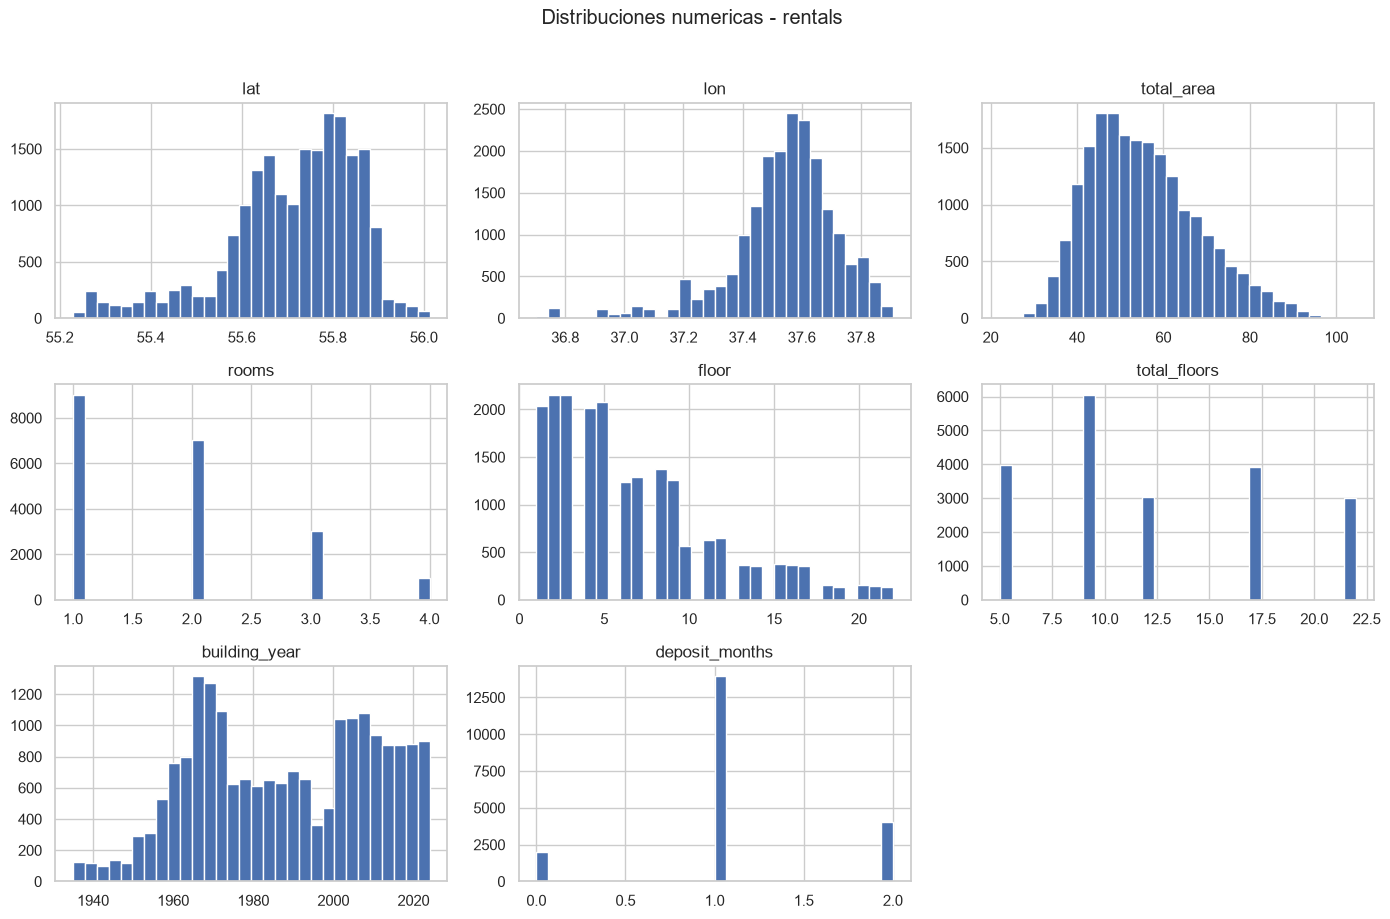

In [8]:
numeric_cols = rentals.select_dtypes(include=np.number).columns[:8]

if len(numeric_cols) > 0:
    rentals[numeric_cols].hist(figsize=(14, 9), bins=30)
    plt.suptitle('Distribuciones numericas - rentals', y=1.02)
    plt.tight_layout()
    plt.show()

## Variables categoricas

In [9]:
for col in rentals.select_dtypes(exclude=np.number).columns[:10]:
    print(f'\n{col}')
    display(rentals[col].value_counts(dropna=False).head(10).to_frame('cantidad'))


id


,cantidad
id,
R000001,1
R000002,1
R000003,1
R000004,1
R000005,1
R000006,1
R000007,1
R000008,1
R000009,1



date_posted


,cantidad
date_posted,
2023-11-11,22
2024-03-18,21
2021-04-02,21
2026-03-24,21
2023-12-07,21
2023-06-06,21
2023-05-08,21
2022-09-29,20
2023-12-12,20



district


...

,cantidad
pets_allowed,
False,13943
True,6057



metro_station


,cantidad
metro_station,
Sviblovo,385
Rechnoy Vokzal,381
Ulitsa Akademika Yangelya,328
Yasenevo,326
Novye Cheryomushki,325
Perovo,322
Tyoply Stan,310
Shchyolkovskaya,299
Nagornaya,291



metro_line


,cantidad
metro_line,
Kaluzhsko-Rizhskaya,2828
Serpukhovsko-Timiryazevskaya,2755
Sokolnicheskaya,2524
Arbatsko-Pokrovskaya,2365
Zamoskvoretskaya,2026
Koltsevaya,1719
Filyovskaya,1595
Tagansko-Krasnopresnenskaya,1364
Lyublinsko-Dmitrovskaya,1125


## Variables candidatas de alquiler

In [10]:
tokens_alquiler = ['rent', 'rental', 'price', 'cost', 'value']
rent_cols = [col for col in rentals.columns if any(token in col.lower() for token in tokens_alquiler)]

print(rent_cols)
if rent_cols:
    display(rentals[rent_cols].describe().T)

['monthly_rent_rub', 'rent_per_sqm']


,count,mean,std,min,25%,50%,75%,max
monthly_rent_rub,20000.0,52432.8550,30003.240405,6800.0,32800.0,45800.0,64400.0,300700.0
rent_per_sqm,20000.0,945.4612,480.537062,148.0,644.0,845.0,1135.0,4264.0


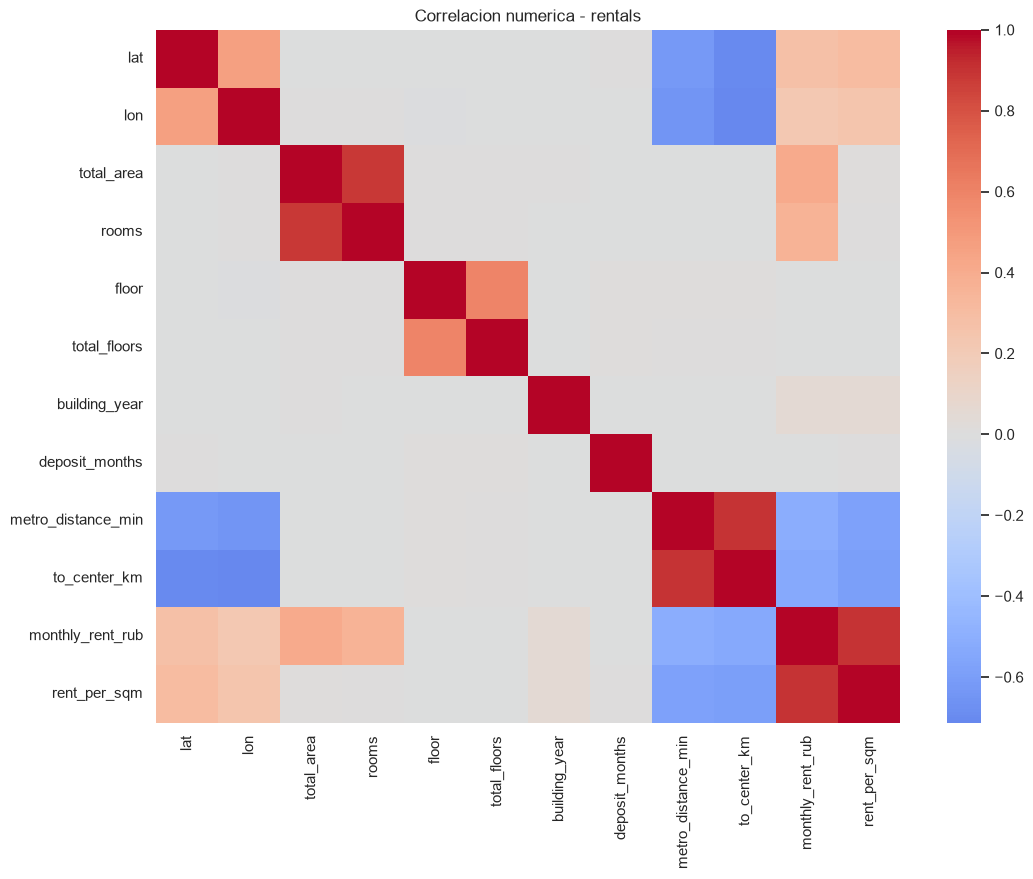

In [11]:
numeric_cols = rentals.select_dtypes(include=np.number).columns

if len(numeric_cols) >= 2:
    corr = rentals[numeric_cols].corr(numeric_only=True)
    plt.figure(figsize=(12, 9))
    sns.heatmap(corr, cmap='coolwarm', center=0)
    plt.title('Correlacion numerica - rentals')
    plt.show()

## Notas para continuar

- Identificar columna objetivo de alquiler mensual.
- Revisar outliers en alquiler, superficie, habitaciones y distancia a metro/centro si existen.
- Definir llaves utiles para unir informacion de distritos, precios mensuales o estaciones de metro.
- Documentar variables que requieren limpieza antes de modelado.